# Tiamat: previsão de renda acima de 50 mil dólares com aprendizado de máquina

**Autora:** ✏️ NOME COMPLETO DA AUTORA — Ilum Escola de Ciência, Centro Nacional de Pesquisa em Energia e Materiais (CNPEM)

Projeto final ("Criatura lendária: Tiamat") da disciplina **ATP-203 Aprendizado de Máquina**, ministrada pelo Prof. Daniel R. Cassar na Ilum Escola de Ciência, em outubro de 2026.

**Resumo.** Este trabalho compara seis algoritmos de aprendizado supervisionado e um modelo de referência na tarefa de prever se uma pessoa recebe mais de 50 mil dólares por ano, a partir de 13 atributos do censo dos Estados Unidos (dados de 1994). Os hiperparâmetros de cada algoritmo, incluindo a normalização dos atributos e a redução de dimensionalidade, foram otimizados com o optuna em 100 configurações distintas por algoritmo, sempre com validação cruzada estratificada apenas no treino. O gradient boosting teve o melhor desempenho, com acurácia balanceada de 0,840 na validação cruzada repetida e de 0,840 no teste (IC 95 %: 0,829 a 0,850) e ROC AUC de 0,925. O modelo passou por um teste de aleatorização do alvo e suas previsões foram interpretadas com importância por permutação, valores SHAP, dependência parcial e uma análise de desempenho por grupo, que revelou diferenças de sensibilidade entre homens e mulheres.

## 1. Introdução

Decisões sobre crédito, contratação, concessão de benefícios e formulação de políticas públicas dependem, em grande medida, de estimativas sobre a renda das pessoas. O censo é uma das principais fontes para entender como a renda se distribui em uma população, e as pesquisas domiciliares que o alimentam registram, ao mesmo tempo, características demográficas, educacionais e ocupacionais de cada indivíduo. Quando essas características são organizadas em uma tabela, surge uma pergunta natural para o aprendizado de máquina: é possível prever a faixa de renda de uma pessoa a partir do que se sabe sobre ela?

Essa pergunta tem valor prático, mas também exige cuidado. Um modelo que prevê renda pode orientar decisões, e um erro sistemático pode prejudicar grupos específicos. Além disso, a renda é influenciada por fatores históricos, institucionais e sociais que não aparecem na tabela, como discriminação no mercado de trabalho, acesso desigual à educação e heranças familiares. Um classificador treinado sobre esses dados aprende associações presentes na realidade, e não relações causais. É essa distinção que determina o que se pode concluir a partir dos resultados.

O problema tratado neste trabalho é de classificação binária. Dados os atributos de uma pessoa, como idade, escolaridade, ocupação, estado civil, horas trabalhadas por semana e ganhos de capital, o modelo deve dizer se o rendimento anual dela é superior a 50 mil dólares. Essa classe corresponde a um limiar muito usado em estudos sobre desigualdade, e é minoritária, com cerca de um quarto das pessoas. Essa assimetria torna a acurácia simples uma métrica enganosa e motiva o uso da acurácia balanceada como medida principal.

O objetivo geral é comparar algoritmos de aprendizado supervisionado nessa tarefa, com ajuste sistemático de hiperparâmetros, e avaliar se o melhor deles generaliza para dados não vistos. Especificamente, o trabalho compara seis algoritmos de famílias diferentes (regressão logística, k vizinhos mais próximos, árvore de decisão, floresta aleatória, gradient boosting e LightGBM) com um modelo de referência que sempre prevê a classe majoritária. Os hiperparâmetros de cada algoritmo, incluindo a normalização dos atributos numéricos, a codificação dos categóricos e a redução de dimensionalidade, são otimizados em 100 configurações distintas por algoritmo. Em seguida, verifica-se se as diferenças de desempenho são estatisticamente relevantes por validação cruzada repetida, avalia-se o modelo escolhido uma única vez em um conjunto de teste reservado desde o início, confirma-se que ele aprendeu um padrão real e não um artefato do procedimento de validação, e examina-se se o desempenho é uniforme entre grupos de sexo e raça.

O conjunto de dados utilizado é o Adult, também conhecido como Census Income, disponível no UCI Machine Learning Repository e derivado de uma extração da Current Population Survey de 1994 (Becker e Kohavi, 1996). O arquivo de treino original tem 32.561 registros, dos quais 30.139 permanecem após a remoção de valores ausentes e de duplicatas exatas. Cada registro traz 13 atributos utilizados pelo modelo, cinco numéricos e oito categóricos. O peso amostral do censo, `fnlwgt`, foi deliberadamente excluído, porque descreve a representatividade do registro na população e não uma característica da pessoa. Esse conjunto é amplamente estudado, o que permite comparar os resultados com a literatura, e reúne atributos mistos, valores ausentes e forte assimetria, o que aproxima o trabalho de situações reais. Ao mesmo tempo, é um conjunto antigo: os registros refletem o mercado de trabalho e a estrutura social dos Estados Unidos de 1994, e não devem ser lidos como retrato do presente.

O notebook segue a ordem de um estudo completo. As seções 2 e 3 descrevem os dados e o ambiente de trabalho. As seções 4 a 6 tratam da verificação, da limpeza, da divisão treino e teste e da análise exploratória, feita apenas sobre o treino. A seção 7 define as métricas e a seção 8 apresenta o modelo de referência. As seções 9 a 11 descrevem os algoritmos, o espaço de busca e a otimização com o optuna. As seções 12 e 13 comparam os algoritmos por validação cruzada repetida e avaliam o modelo final no teste. A seção 14 traz o teste de aleatorização do alvo, e a seção 15 reúne a interpretação, incluindo a análise por grupo. As seções 16 a 18 discutem limitações, o uso de inteligência artificial e as conclusões, e a seção 19 lista as referências.

Uma decisão metodológica atravessa todo o trabalho e merece destaque desde já. Para viabilizar a busca de hiperparâmetros em duas CPUs dentro do prazo, a otimização e a comparação foram feitas sobre uma subamostra estratificada de 6.000 registros do treino, enquanto o modelo final foi reajustado no treino completo. Essa concessão é discutida na seção 16 e deve ser considerada na interpretação dos resultados.

## 2. O conjunto de dados

O conjunto de dados **Adult** (também chamado Census Income) foi extraído da base da Current Population Survey de 1994 pelo Census Bureau dos Estados Unidos e preparado por Ronny Kohavi e Barry Becker. Ele está disponível no UCI Machine Learning Repository (Becker e Kohavi, 1996) e é uma referência clássica em estudos de classificação e de equidade algorítmica.

O arquivo usado neste projeto é o **`adult.data`**, com **32.561 registros**. O site da UCI não estava acessível no ambiente em que o trabalho foi feito, então o arquivo foi obtido de uma cópia do mesmo conjunto de dados, distribuída pelo pacote `pytorch-widedeep`. Essa cópia foi conferida contra as contagens publicadas pelo UCI para o conjunto completo: 48.842 registros no total, 3.620 com valores ausentes e 23,93 % de renda acima de 50 mil dólares. Os valores são os mesmos, mas o separador foi reescrito sem o espaço que o UCI coloca depois das vírgulas. Cada registro descreve uma pessoa por 14 atributos e pela renda anual, que é o alvo. O UCI traz também o arquivo `adult.test` com 16.281 registros; ele não é usado aqui, porque a divisão treino/teste do projeto é feita a partir do `adult.data`, de forma estratificada e controlada pela semente.

Os atributos são:

| Atributo | Tipo | Descrição |
|---|---|---|
| `age` | numérico | Idade em anos |
| `workclass` | categórico | Tipo de vínculo de trabalho |
| `fnlwgt` | numérico | Peso amostral do censo (não é usado como atributo, ver seção 4.1) |
| `education` | categórico | Nível de escolaridade |
| `educational-num` | numérico | Anos de estudo |
| `marital-status` | categórico | Estado civil |
| `occupation` | categórico | Ocupação |
| `relationship` | categórico | Papel na família |
| `race` | categórico | Raça autodeclarada |
| `gender` | categórico | Sexo |
| `capital-gain` | numérico | Ganho de capital no ano |
| `capital-loss` | numérico | Perda de capital no ano |
| `hours-per-week` | numérico | Horas trabalhadas por semana |
| `native-country` | categórico | País de origem |
| `income` | alvo | `>50K` ou `<=50K` |

Os valores ausentes aparecem como `?` e ocorrem em `workclass`, `occupation` e `native-country`. A classe positiva, renda acima de 50 mil dólares, é minoritária, com cerca de um quarto dos registros.

## 3. Bibliotecas e configuração

Todas as etapas com aleatoriedade usam a semente 42. As versões das bibliotecas estão fixadas em `requirements.txt` e são impressas na célula abaixo, para que o resultado possa ser reproduzido.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
import sklearn
from scipy import stats
from optuna.trial import TrialState
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score,
                             confusion_matrix, make_scorer, matthews_corrcoef, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate

INICIO_NOTEBOOK = time.perf_counter()
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*vert: bool.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)

sys.path.insert(0, str(Path.cwd()))
from codigo.dados import (ATRIBUTOS, ATRIBUTOS_CATEGORICOS, ATRIBUTOS_NUMERICOS, AMOSTRA_BUSCA, SEMENTE,
                          amostra_busca, carregar_treino_teste, ler_dados_brutos, preparar_dados,
                          dividir_treino_teste, DESCRICOES)
from codigo.otimizar import N_CONFIGURACOES, url_banco, validacao_cruzada_otimizacao
from codigo.pipelines import MODELOS, NOMES_CURTOS, criar_preprocessamento, pipeline_com_parametros

PASTA_FIGURAS = Path("figuras")
PASTA_FIGURAS.mkdir(exist_ok=True)

# Paleta Okabe-Ito (amigável a daltonismo), usada em todas as figuras.
CORES = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 11})

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| optuna", optuna.__version__, "| shap", shap.__version__)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.13.16 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | optuna 5.0.0 | shap 0.52.0


## 4. Leitura e verificação

Antes de qualquer transformação, verifica-se o formato do arquivo, a presença de valores ausentes e a existência de duplicatas.

In [2]:
df_bruto = ler_dados_brutos()
print("Formato do arquivo bruto:", df_bruto.shape)
print("\nPrimeiras linhas:")
display(df_bruto.head(3))
print("\nValores ausentes ('?') por atributo:")
print(df_bruto.isna().sum()[lambda s: s > 0].to_string())
print("\nRegistros com pelo menos um valor ausente:", int(df_bruto.isna().any(axis=1).sum()))
print("Duplicatas exatas (todas as 15 colunas) antes da limpeza:", int(df_bruto.duplicated().sum()))
print("Duplicatas exatas (todas as 15 colunas) depois de remover ausentes:",
      int(df_bruto.dropna().duplicated().sum()))

Formato do arquivo bruto: (32561, 15)

Primeiras linhas:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K



Valores ausentes ('?') por atributo:
workclass         1836
occupation        1843
native-country     583

Registros com pelo menos um valor ausente: 2399
Duplicatas exatas (todas as 15 colunas) antes da limpeza: 24
Duplicatas exatas (todas as 15 colunas) depois de remover ausentes: 23


### 4.1 Limpeza e separação de atributos e alvo

Os registros com valor ausente são removidos, porque são uma parcela pequena do total e imputar valores em atributos categóricos exigiria escolhas arbitrárias. Registros idênticos em todas as 15 colunas são tratados como duplicatas e mantidos uma única vez.

O atributo `fnlwgt` não entra no modelo. Ele é o peso amostral do censo, ou seja, quantas pessoas da população cada registro representa. Ele não descreve a pessoa e serve para corrigir a amostra em estatísticas populacionais, não para prever renda. Os demais 13 atributos são usados.

In [3]:
X, y = preparar_dados(df_bruto)
print(f"Registros após limpeza: {X.shape[0]} | atributos: {X.shape[1]} | "
      f"proporção de renda > 50 mil: {y.mean():.1%}")
print(f"Atributos numéricos ({len(ATRIBUTOS_NUMERICOS)}): {ATRIBUTOS_NUMERICOS}")
print(f"Atributos categóricos ({len(ATRIBUTOS_CATEGORICOS)}): {ATRIBUTOS_CATEGORICOS}")
print("\nTipos de dados:")
print(X.dtypes.value_counts().to_string())

Registros após limpeza: 30139 | atributos: 13 | proporção de renda > 50 mil: 24.9%
Atributos numéricos (5): ['age', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Atributos categóricos (8): ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country']

Tipos de dados:
str      8
int64    5


## 5. Divisão treino e teste

Os dados são divididos em 80 % para treino e 20 % para teste, de forma estratificada, para que a proporção de rendas altas seja igual nos dois conjuntos. O conjunto de teste fica guardado e só é usado uma vez, na seção 13. Toda a análise exploratória, a busca de hiperparâmetros e a comparação de algoritmos usam apenas o treino.

In [4]:
X_treino, X_teste, y_treino, y_teste = dividir_treino_teste(X, y)
resumo_divisao = pd.DataFrame({
    "conjunto": ["treino", "teste", "total"],
    "registros": [len(X_treino), len(X_teste), len(X)],
    "renda > 50 mil (%)": [100 * y_treino.mean(), 100 * y_teste.mean(), 100 * y.mean()],
})
resumo_divisao["renda > 50 mil (%)"] = resumo_divisao["renda > 50 mil (%)"].round(2)
display(resumo_divisao)

,conjunto,registros,renda > 50 mil (%)
0,treino,24111,24.91
1,teste,6028,24.90
2,total,30139,24.90


## 6. Análise exploratória (apenas o treino)

Esta seção descreve os dados de treino para orientar as escolhas de pré-processamento. Nenhuma decisão de modelagem é tomada com base no teste.

### 6.1 Distribuição do alvo

A classe de renda acima de 50 mil dólares é minoritária. Um classificador que sempre responde a classe majoritária acerta cerca de três de cada quatro previsões, mas não identifica nenhuma pessoa de alta renda. Por isso a métrica principal do trabalho é a acurácia balanceada (seção 7).

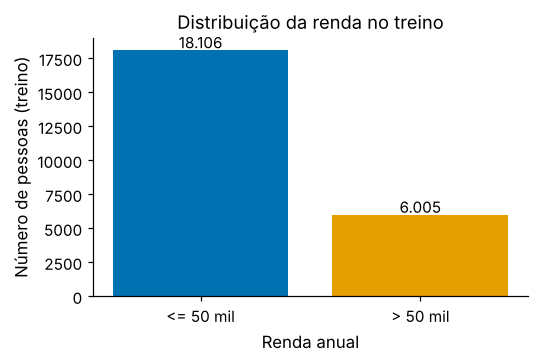

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.4))
contagem = y_treino.map({0: "<= 50 mil", 1: "> 50 mil"}).value_counts().loc[["<= 50 mil", "> 50 mil"]]
ax.bar(contagem.index, contagem.values, color=[CORES[0], CORES[1]])
for i, v in enumerate(contagem.values):
    ax.text(i, v + 150, f"{v:,}".replace(",", "."), ha="center")
ax.set_xlabel("Renda anual")
ax.set_ylabel("Número de pessoas (treino)")
ax.set_title("Distribuição da renda no treino")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "distribuicao_alvo.png", dpi=150)
plt.show()

### 6.2 Atributos numéricos

Cerca de 92 % das pessoas do treino têm ganho de capital igual a zero, e cerca de 95 % têm perda de capital igual a zero. Os valores não nulos são poucos e muito altos, o que motiva a comparação entre padronização e transformação por quantis na etapa de pré-processamento (seção 10.1). Os histogramas usam escala logarítmica no eixo vertical para que as barras pequenas sejam visíveis.

,count,mean,std,min,25%,50%,75%,max
age,24111.0,38.5,13.2,17.0,28.0,37.0,47.0,90.0
educational-num,24111.0,10.1,2.5,1.0,9.0,10.0,13.0,16.0
capital-gain,24111.0,1118.6,7633.0,0.0,0.0,0.0,0.0,99999.0
capital-loss,24111.0,88.4,404.0,0.0,0.0,0.0,0.0,3770.0
hours-per-week,24111.0,40.9,12.0,1.0,40.0,40.0,45.0,99.0


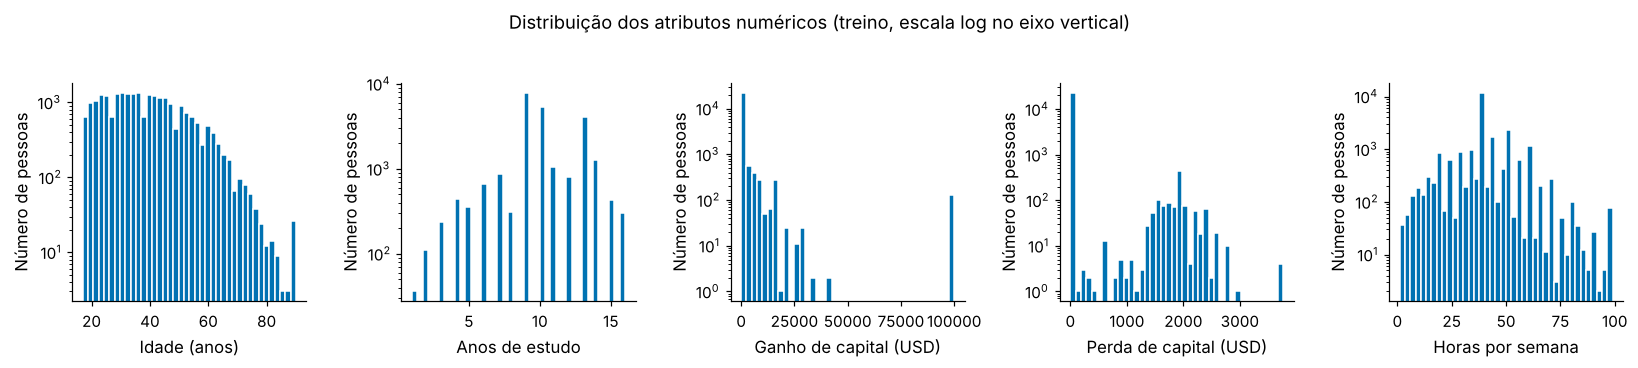

Proporção de ganho de capital igual a zero: 91.6%
Proporção de perda de capital igual a zero: 95.3%


In [6]:
numericos = X_treino[ATRIBUTOS_NUMERICOS]
display(numericos.describe().T.round(1))

fig, eixos = plt.subplots(1, len(ATRIBUTOS_NUMERICOS), figsize=(15, 3.2))
rotulos = {"age": "Idade (anos)", "educational-num": "Anos de estudo",
           "capital-gain": "Ganho de capital (USD)", "capital-loss": "Perda de capital (USD)",
           "hours-per-week": "Horas por semana"}
for eixo, atributo in zip(eixos, ATRIBUTOS_NUMERICOS):
    eixo.hist(X_treino[atributo], bins=40, color=CORES[0], edgecolor="white")
    eixo.set_xlabel(rotulos[atributo])
    eixo.set_ylabel("Número de pessoas")
    eixo.set_yscale("log")
fig.suptitle("Distribuição dos atributos numéricos (treino, escala log no eixo vertical)", y=1.03)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "distribuicao_numericos.png", dpi=150, bbox_inches="tight")
plt.show()

print("Proporção de ganho de capital igual a zero:", f"{(X_treino['capital-gain'] == 0).mean():.1%}")
print("Proporção de perda de capital igual a zero:", f"{(X_treino['capital-loss'] == 0).mean():.1%}")

### 6.3 Renda por categoria

Os gráficos mostram a proporção de pessoas com renda acima de 50 mil dólares em cada categoria. Diferenças grandes entre categorias indicam atributos com potencial de previsão, mas não provam relação causal: a escolaridade e a ocupação, por exemplo, estão associadas à renda por motivos históricos e institucionais que estão além dos dados.

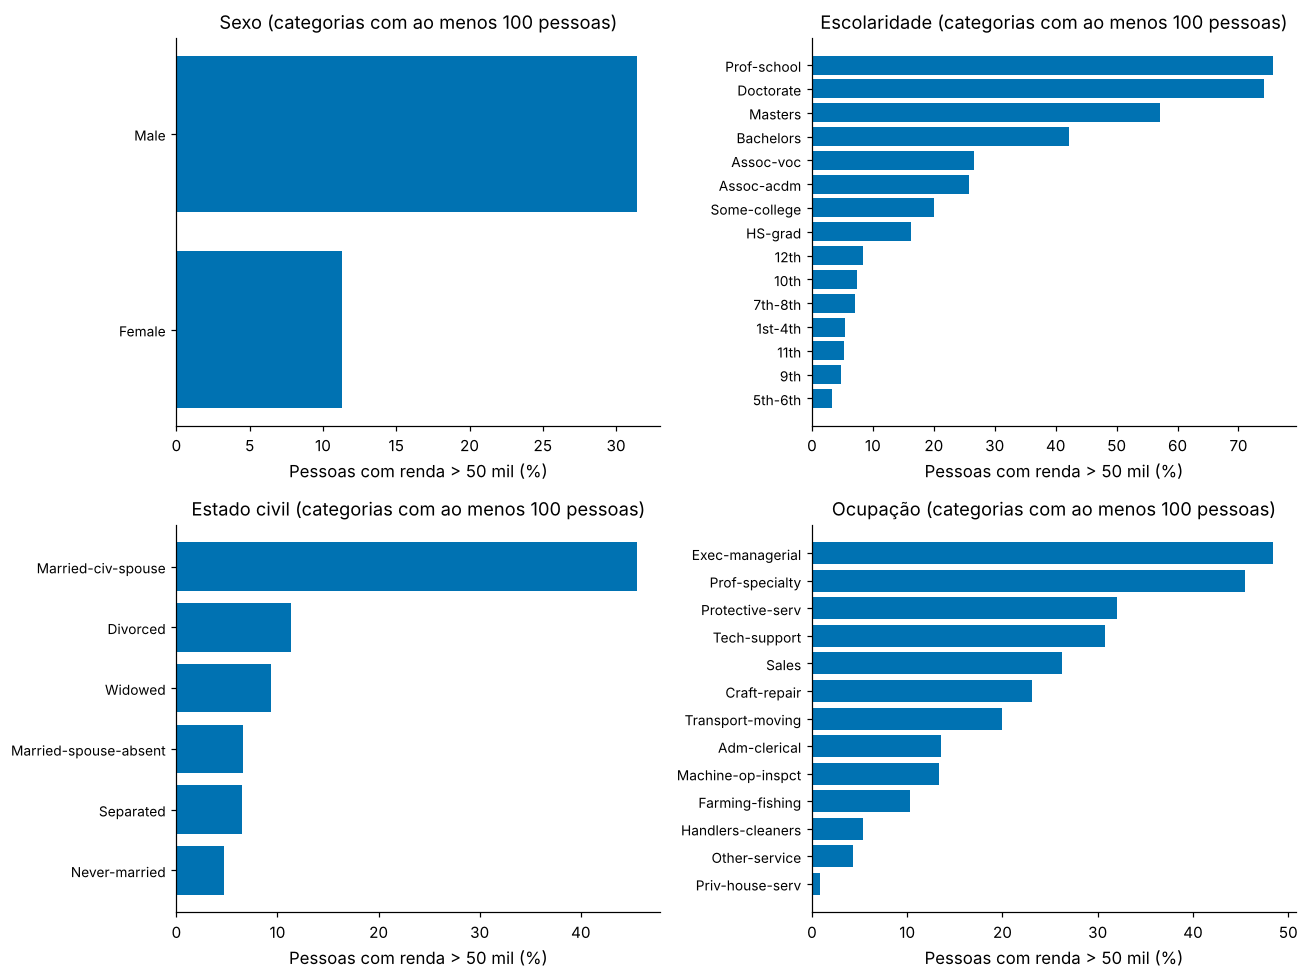

In [7]:
def taxa_alta_renda(atributo, ordenar_por_taxa=True):
    tabela = (pd.DataFrame({"categoria": X_treino[atributo], "alta": y_treino})
              .groupby("categoria")["alta"].agg(["mean", "size"]))
    tabela = tabela[tabela["size"] >= 100]  # só categorias com ao menos 100 pessoas
    if ordenar_por_taxa:
        tabela = tabela.sort_values("mean")
    return tabela

fig, eixos = plt.subplots(2, 2, figsize=(12, 9))
for eixo, atributo, titulo in zip(eixos.flat,
                                  ["gender", "education", "marital-status", "occupation"],
                                  ["Sexo", "Escolaridade", "Estado civil", "Ocupação"]):
    tabela = taxa_alta_renda(atributo)
    eixo.barh(tabela.index.astype(str), 100 * tabela["mean"], color=CORES[0])
    eixo.set_xlabel("Pessoas com renda > 50 mil (%)")
    eixo.set_title(titulo + " (categorias com ao menos 100 pessoas)")
    eixo.tick_params(axis="y", labelsize=9)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "taxa_alta_renda_por_categoria.png", dpi=150)
plt.show()

## 7. Métrica de avaliação

A métrica principal é a **acurácia balanceada**, a média entre a sensibilidade (proporção de pessoas de alta renda identificadas) e a especificidade (proporção de pessoas de baixa renda identificadas). Como a classe positiva é minoritária, a acurácia simples recompensaria o modelo que sempre prevê baixa renda. A acurácia balanceada vale 0,5 para esse modelo trivial, o que serve de referência.

Como métricas complementares, o trabalho reporta a **área sob a curva ROC** (ROC AUC), que mede a capacidade de ordenar as pessoas por probabilidade de alta renda independentemente do limiar de decisão, e o **coeficiente de correlação de Matthews** (MCC), que resume a matriz de confusão em um único valor entre -1 e 1.

In [8]:
METRICAS = {
    "acuracia_balanceada": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "mcc": make_scorer(matthews_corrcoef),
}
print("Métricas calculadas em cada dobra:", list(METRICAS))

Métricas calculadas em cada dobra: ['acuracia_balanceada', 'roc_auc', 'mcc']


## 8. Modelo de referência

O modelo de referência prevê sempre a classe majoritária (renda até 50 mil dólares). Ele não usa nenhum atributo e serve para verificar se os algoritmos aprendem algo além da proporção das classes. Em validação cruzada e no teste, sua acurácia balanceada é 0,5.

In [9]:
X_busca, y_busca = amostra_busca(X_treino, y_treino)
print(f"Treino completo: {len(X_treino)} | subamostra usada na busca: {len(X_busca)} "
      f"(renda > 50 mil: {y_busca.mean():.1%})")

cv_base = validacao_cruzada_otimizacao()
dummy = DummyClassifier(strategy="most_frequent")
base_cv = cross_validate(dummy, X_busca, y_busca, cv=cv_base, scoring="balanced_accuracy")
base_teste = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
baseline_teste = balanced_accuracy_score(y_teste, base_teste.predict(X_teste))
print(f"Baseline (sempre prevê a classe majoritária, <= 50 mil):")
print(f"  acurácia balanceada em validação cruzada: {base_cv['test_score'].mean():.3f}")
print(f"  acurácia balanceada no teste: {baseline_teste:.3f}")

Treino completo: 24111 | subamostra usada na busca: 6000 (renda > 50 mil: 24.9%)
Baseline (sempre prevê a classe majoritária, <= 50 mil):
  acurácia balanceada em validação cruzada: 0.500
  acurácia balanceada no teste: 0.500


## 9. Algoritmos comparados

Foram comparados seis algoritmos de famílias diferentes, para cobrir modelos lineares, baseados em distância, de árvore única, de agregação de árvores e de boosting.

- **Regressão logística** com penalidades L1, L2 ou elastic net: modelo linear de referência, fácil de interpretar.
- **k vizinhos mais próximos (k-NN)**: classifica pela maioria dos vizinhos mais próximos, sem treino explícito.
- **Árvore de decisão**: divide os atributos em regras sucessivas. Uma árvore isolada é fácil de ler, mas tende a se ajustar demais aos dados, por isso a poda é escolhida pelo optuna (Breiman et al., 1984).
- **Floresta aleatória**: média de muitas árvores treinadas em amostras aleatórias de dados e de atributos (Breiman, 2001).
- **Gradient boosting com histogramas**: árvores treinadas em sequência, cada uma corrigindo os erros das anteriores (Friedman, 2001).
- **LightGBM**: implementação de gradient boosting que constrói as árvores por folhas e usa amostragem de linhas e de atributos, o que o torna rápido e eficiente em memória (Ke et al., 2017).

## 10. Pipelines e espaço de busca

### 10.1 Preprocessamento e codificação

Os atributos numéricos passam por uma normalização, escolhida pelo optuna entre padronização (média zero e desvio um) e transformação por quantis, que aproxima cada atributo de uma distribuição normal. Os atributos categóricos são transformados em colunas binárias (*one-hot*), com a categoria ausente no treino tratada como vetor de zeros.

Toda essa etapa fica dentro do pipeline, que é ajustado separadamente em cada dobra da validação cruzada. Assim, médias, quantis e categorias são aprendidos apenas com os dados de treino da dobra, e nada da dobra de validação vaza para o modelo.

In [10]:
pre_demo = criar_preprocessamento(optuna.trial.FixedTrial({"normalizador": "padronizacao"}))
A = pre_demo.fit_transform(X_busca)
print("Atributos antes da codificação:", X_busca.shape[1])
print("Colunas depois do one-hot e da normalização:", A.shape[1])
print("Limite superior usado na redução (MAX_COLUNAS_REDUCAO):", 80)

Atributos antes da codificação: 13
Colunas depois do one-hot e da normalização: 101
Limite superior usado na redução (MAX_COLUNAS_REDUCAO): 80


### 10.2 Espaço de busca

Cada pipeline tem três etapas, todas escolhidas pelo optuna: normalização, redução de dimensionalidade e classificador. A redução pode ser nenhuma, uma seleção dos k melhores atributos por ANOVA ou informação mútua, ou uma análise de componentes principais (PCA). Depois da codificação, a matriz tem 101 colunas (5 numéricas e 96 binárias das categorias). O limite superior da redução foi fixado em 80, abaixo desse total, para que o número de atributos escolhidos nunca ultrapasse o disponível. Os intervalos dos hiperparâmetros seguem as recomendações usuais de cada algoritmo, com escala logarítmica para parâmetros de regularização e de largura de kernel.

In [11]:
espaco = pd.DataFrame([
    ["Normalizador", "padronização ou quantis", "pipeline inteiro"],
    ["Redução", "nenhuma / SelectKBest (k de 5 a 80) / PCA (2 a 80 componentes)", "pipeline inteiro"],
    ["Regressão logística", "C (log, 1e-4 a 1e3), l1_ratio (0 a 1), class_weight", "solver saga"],
    ["k-NN", "k (1 a 100), weights, p (1 ou 2)", ""],
    ["Árvore de decisão", "max_depth (2 a 30), min_samples_leaf (1 a 100), criterion, ccp_alpha (log, 1e-5 a 1e-1), class_weight", "poda por custo-complexidade"],
    ["Floresta aleatória", "n_estimators, max_depth, min_samples_leaf, max_features, criterion, class_weight", ""],
    ["Gradient boosting", "learning_rate, max_iter, max_leaf_nodes, min_samples_leaf, l2_regularization, max_features, class_weight", ""],
    ["LightGBM", "n_estimators (50 a 600), learning_rate (log), num_leaves (log, 4 a 128), min_child_samples, subsample, colsample_bytree, reg_lambda (log), class_weight", "amostragem de linhas e atributos"],
], columns=["Etapa / algoritmo", "Hiperparâmetros e intervalos", "Observação"])
display(espaco)

,Etapa / algoritmo,Hiperparâmetros e intervalos,Observação
0,Normalizador,padronização ou quantis,pipeline inteiro
1,Redução,nenhuma / SelectKBest (k de 5 a 80) / PCA (2 a...,pipeline inteiro
2,Regressão logística,"C (log, 1e-4 a 1e3), l1_ratio (0 a 1), class_w...",solver saga
3,k-NN,"k (1 a 100), weights, p (1 ou 2)",
4,Árvore de decisão,"max_depth (2 a 30), min_samples_leaf (1 a 100)...",poda por custo-complexidade
5,Floresta aleatória,"n_estimators, max_depth, min_samples_leaf, max...",
6,Gradient boosting,"learning_rate, max_iter, max_leaf_nodes, min_s...",
7,LightGBM,"n_estimators (50 a 600), learning_rate (log), ...",amostragem de linhas e atributos


### 10.3 Por que a busca usa uma subamostra

Em um teste preliminar, o ajuste de um SVM com kernel RBF em cerca de 24 mil registros levou cerca de 30 segundos em um computador com duas CPUs. Com 100 configurações e cinco dobras por algoritmo, a busca sobre o treino completo levaria horas e colocaria em risco o prazo de entrega. Por isso, a busca de hiperparâmetros e a comparação por validação cruzada usam uma **subamostra estratificada de 6.000 registros do treino**, com a mesma proporção de rendas altas. O conjunto de teste continua intocado, e o modelo final é reajustado no treino completo antes da avaliação. Essa decisão é uma limitação do trabalho e é discutida na seção 16.

## 11. Otimização com optuna

Para cada algoritmo, o optuna (Akiba et al., 2019) usa o amostrador TPE multivariado (Bergstra et al., 2011) com semente fixa, até completar **100 configurações distintas**. Configurações repetidas são descartadas e não entram na contagem. Cada configuração é avaliada pela acurácia balanceada média em validação cruzada estratificada de cinco dobras, calculada somente com a subamostra de treino. O banco de dados com todas as tentativas está em `resultados/otimizacao_optuna.db`.

In [12]:
storage = url_banco()
estudos = {}
linhas = []
for nome in MODELOS:
    estudo = optuna.load_study(study_name=nome, storage=storage)
    estudos[nome] = estudo
    concluidas = [t for t in estudo.trials if t.state == TrialState.COMPLETE]
    repetidas = [t for t in estudo.trials if t.state == TrialState.PRUNED]
    distintas = {tuple(sorted(t.params.items())) for t in concluidas}
    linhas.append({
        "algoritmo": NOMES_CURTOS[nome],
        "configurações concluídas": len(concluidas),
        "configurações distintas": len(distintas),
        "repetidas descartadas": len(repetidas),
        "melhor acurácia balanceada (CV)": round(estudo.best_value, 4),
        "tempo total (min)": round(sum(t.duration.total_seconds() for t in estudo.trials
                                       if t.duration is not None) / 60, 1),
    })
    assert len(concluidas) == N_CONFIGURACOES and len(distintas) == N_CONFIGURACOES, nome

resumo_otimizacao = pd.DataFrame(linhas).sort_values("melhor acurácia balanceada (CV)", ascending=False)
display(resumo_otimizacao.reset_index(drop=True))

,algoritmo,configurações concluídas,configurações distintas,repetidas descartadas,melhor acurácia balanceada (CV),tempo total (min)
0,LightGBM,100,100,0,0.8425,1.4
1,Gradient boosting,100,100,0,0.8417,8.6
2,Floresta aleatória,100,100,0,0.8314,11.1
3,Reg. logística,100,100,0,0.8227,15.1
4,Árvore de decisão,100,100,0,0.8159,0.8
5,k-NN,100,100,3,0.7758,2.0


### 11.1 Histórico da otimização

Os gráficos mostram a acurácia de cada configuração na ordem em que foi testada e a melhor acurácia até aquele momento. Uma curva que se estabiliza indica que a busca encontrou uma região boa do espaço de hiperparâmetros, embora não garanta que o ótimo global tenha sido atingido.

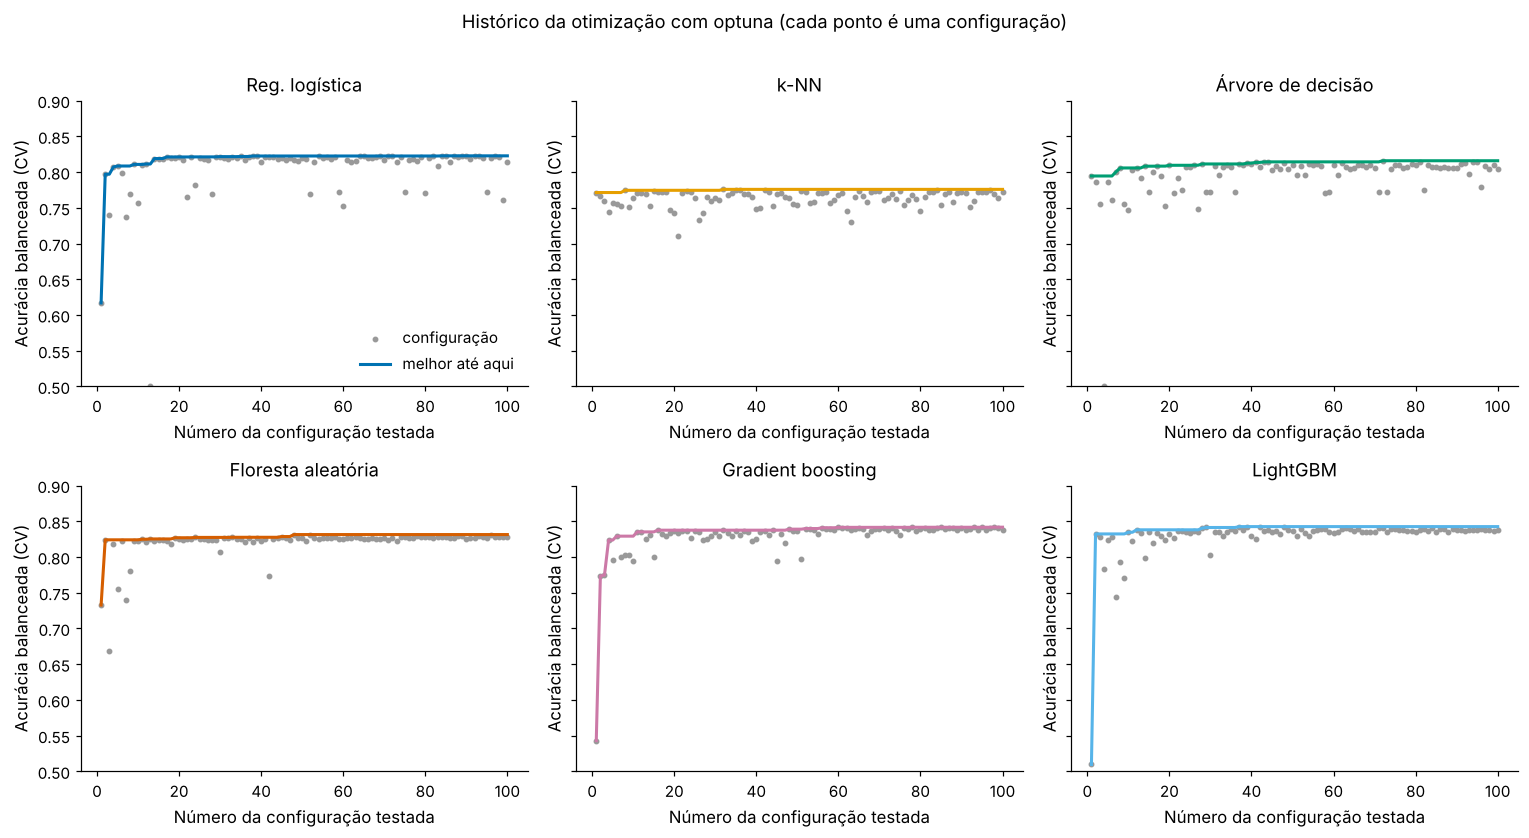

In [13]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 7.5), sharey=True)
for eixo, (nome, estudo), cor in zip(eixos.flat, estudos.items(), CORES):
    concluidas = [t for t in estudo.trials if t.state == TrialState.COMPLETE]
    valores = [t.value for t in concluidas]
    melhor_ate_agora = np.maximum.accumulate(valores)
    eixo.scatter(range(1, len(valores) + 1), valores, s=8, color="0.6", label="configuração")
    eixo.plot(range(1, len(valores) + 1), melhor_ate_agora, color=cor, lw=2, label="melhor até aqui")
    eixo.set_title(NOMES_CURTOS[nome])
    eixo.set_xlabel("Número da configuração testada")
    eixo.set_ylabel("Acurácia balanceada (CV)")
    eixo.set_ylim(0.5, 0.9)
eixos[0, 0].legend(frameon=False, loc="lower right")
fig.suptitle("Histórico da otimização com optuna (cada ponto é uma configuração)", y=1.01)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "historico_otimizacao.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Comparação por validação cruzada repetida

Para comparar os algoritmos com a melhor configuração de cada um, usa-se validação cruzada estratificada de cinco dobras repetida dez vezes, com 50 avaliações por algoritmo. As dobras são as mesmas para todos os algoritmos, o que permite comparações pareadas.

In [14]:
MELHORES_PARAMETROS = {nome: estudo.best_params for nome, estudo in estudos.items()}
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMENTE)

resultados_rep = {}
for nome in MODELOS:
    pipeline = pipeline_com_parametros(nome, MELHORES_PARAMETROS[nome])
    resultado = cross_validate(pipeline, X_busca, y_busca, cv=rskf, scoring="balanced_accuracy")
    resultados_rep[nome] = resultado["test_score"]

tabela_rep = pd.DataFrame({
    "algoritmo": [NOMES_CURTOS[n] for n in MODELOS],
    "média": [resultados_rep[n].mean() for n in MODELOS],
    "desvio-padrão": [resultados_rep[n].std(ddof=1) for n in MODELOS],
}, index=list(MODELOS)).sort_values("média", ascending=False)
display(tabela_rep.round(4))

,algoritmo,média,desvio-padrão
gradient_boosting,Gradient boosting,0.8397,0.0102
lightgbm,LightGBM,0.8377,0.0105
floresta_aleatoria,Floresta aleatória,0.8281,0.0107
regressao_logistica,Reg. logística,0.8211,0.0107
arvore_decisao,Árvore de decisão,0.8110,0.0100
knn,k-NN,0.7717,0.0142


### 12.1 Teste t de Nadeau e Bengio e correção de Holm

As 50 avaliações não são independentes, porque dobras de repetições diferentes compartilham dados. O teste t comum superestima a significância nesse caso. Por isso usa-se a correção de Nadeau e Bengio (2003), que aumenta a variância da diferença média pelo fator (1/J + n_teste/n_treino). Como são feitas várias comparações contra o melhor algoritmo, os valores-p são ajustados pelo método de Holm (1979).

In [15]:
def teste_t_nadeau_bengio(a, b, n_treino, n_teste):
    """Teste t pareado com a correção de Nadeau e Bengio para validação cruzada repetida."""
    diferencas = np.asarray(a) - np.asarray(b)
    j = len(diferencas)
    variancia_corrigida = (1 / j + n_teste / n_treino) * diferencas.var(ddof=1)
    t = diferencas.mean() / np.sqrt(variancia_corrigida)
    p = 2 * stats.t.sf(np.abs(t), df=j - 1)
    return t, p

def ajuste_holm(valores_p):
    """Ajuste de Holm para várias comparações."""
    ordem = np.argsort(valores_p)
    m = len(valores_p)
    ajustados = np.empty(m)
    maximo = 0.0
    for rank, i in enumerate(ordem):
        ajuste = min(1.0, (m - rank) * valores_p[i])
        maximo = max(maximo, ajuste)
        ajustados[i] = maximo
    return ajustados

melhor = tabela_rep.index[0]
n_treino_cv = int(len(X_busca) * 0.8)
n_teste_cv = len(X_busca) - n_treino_cv
linhas_comp, p_brutos = [], []
for nome in MODELOS:
    if nome == melhor:
        continue
    t, p = teste_t_nadeau_bengio(resultados_rep[melhor], resultados_rep[nome], n_treino_cv, n_teste_cv)
    linhas_comp.append({"comparação": f"{NOMES_CURTOS[melhor]} vs {NOMES_CURTOS[nome]}",
                        "diferença média": resultados_rep[melhor].mean() - resultados_rep[nome].mean(),
                        "estatística t": t, "valor-p bruto": p})
    p_brutos.append(p)
tabela_comp = pd.DataFrame(linhas_comp)
tabela_comp["valor-p (Holm)"] = ajuste_holm(np.array(p_brutos))
display(tabela_comp.round(4))
print("Melhor algoritmo na validação cruzada repetida:", NOMES_CURTOS[melhor])

,comparação,diferença média,estatística t,valor-p bruto,valor-p (Holm)
0,Gradient boosting vs Reg. logística,0.0185,5.6096,0.0000,0.0000
1,Gradient boosting vs k-NN,0.0679,9.3402,0.0000,0.0000
2,Gradient boosting vs Árvore de decisão,0.0286,5.7721,0.0000,0.0000
3,Gradient boosting vs Floresta aleatória,0.0116,2.8918,0.0057,0.0114
4,Gradient boosting vs LightGBM,0.0020,0.5242,0.6025,0.6025


Melhor algoritmo na validação cruzada repetida: Gradient boosting


**Leitura.** O gradient boosting teve a maior média (0,840 ± 0,010), seguido de perto pelo LightGBM (0,838 ± 0,011). A diferença entre os dois é de 0,002 e não é significativa (valor-p ajustado de 0,60), de modo que a escolha entre eles é indiferente para esses dados. A floresta aleatória (0,828) e a regressão logística (0,821) ficam em seguida, a árvore de decisão isolada tem 0,811 e o k-NN, 0,772. O gradient boosting é estatisticamente superior à floresta aleatória (valor-p ajustado de 0,011), à regressão logística, à árvore e ao k-NN. Como a tabela compara cada algoritmo com o melhor, ela não mede as diferenças entre os demais.

### 12.2 Distribuição das acurácias

O gráfico mostra a dispersão das 50 acurácias de cada algoritmo. A linha tracejada marca o baseline.

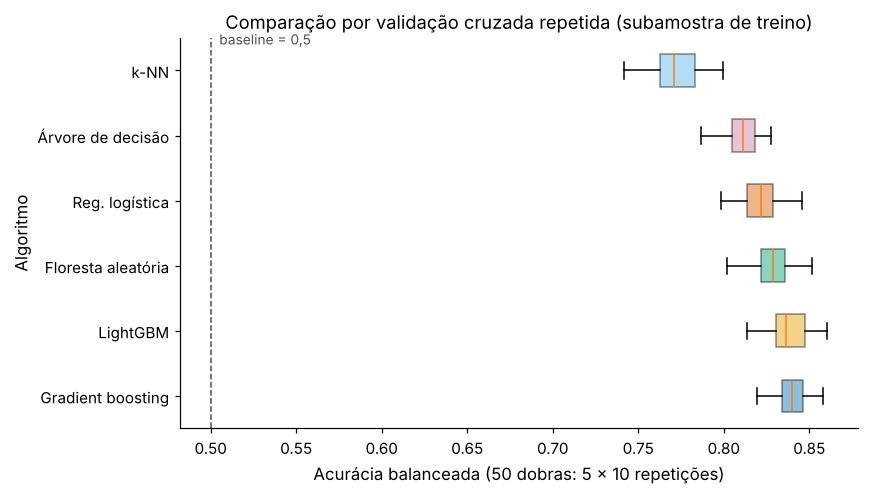

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ordem = list(tabela_rep.index)
dados_box = [resultados_rep[n] for n in ordem]
caixas = ax.boxplot(dados_box, orientation="horizontal", patch_artist=True, tick_labels=[NOMES_CURTOS[n] for n in ordem])
for caixa, cor in zip(caixas["boxes"], CORES * 2):
    caixa.set_facecolor(cor)
    caixa.set_alpha(0.45)
ax.axvline(0.5, color="0.3", ls="--", lw=1)
ax.text(0.505, len(ordem) + 0.4, "baseline = 0,5", fontsize=9, color="0.3")
ax.set_xlabel("Acurácia balanceada (50 dobras: 5 × 10 repetições)")
ax.set_ylabel("Algoritmo")
ax.set_title("Comparação por validação cruzada repetida (subamostra de treino)")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "comparacao_validacao_cruzada.png", dpi=150)
plt.show()

## 13. Avaliação final no conjunto de teste

O algoritmo com maior média na validação cruzada repetida é reajustado no treino completo com os hiperparâmetros escolhidos e avaliado uma única vez no teste. O intervalo de confiança da acurácia balanceada é obtido por reamostragem bootstrap com 2.000 repetições das previsões do teste.

,métrica,valor
0,acurácia balanceada,0.840
1,IC 95 % (bootstrap),[0.829; 0.850]
2,sensibilidade (renda > 50 mil),0.856
3,especificidade (renda <= 50 mil),0.825
4,ROC AUC,0.925
5,MCC,0.619
6,acurácia simples,0.832


Matriz de confusão (teste): TN 3733 | FP 794 | FN 216 | TP 1285


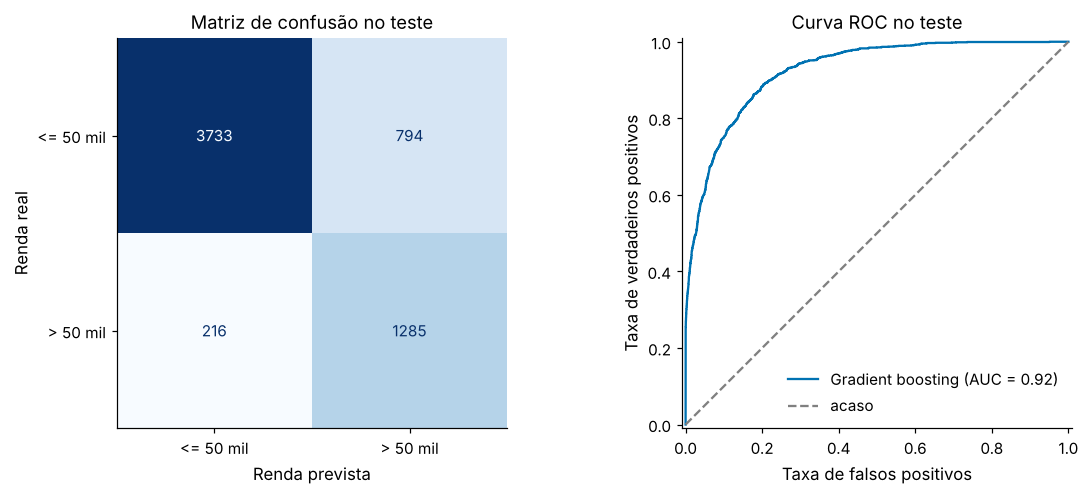

In [17]:
modelo_final = pipeline_com_parametros(melhor, MELHORES_PARAMETROS[melhor])
modelo_final.fit(X_treino, y_treino)  # refit no treino COMPLETO, com os hiperparâmetros escolhidos

prob = modelo_final.predict_proba(X_teste)[:, 1]
pred = modelo_final.predict(X_teste)
tn, fp, fn, tp = confusion_matrix(y_teste, pred).ravel()

acuracia_bal = balanced_accuracy_score(y_teste, pred)
rng = np.random.default_rng(SEMENTE)
amostras = []
for _ in range(2000):
    idx = rng.integers(0, len(y_teste), len(y_teste))
    amostras.append(balanced_accuracy_score(y_teste.iloc[idx], pred[idx]))
ic_inf, ic_sup = np.percentile(amostras, [2.5, 97.5])

metricas_teste = pd.DataFrame({
    "métrica": ["acurácia balanceada", "IC 95 % (bootstrap)", "sensibilidade (renda > 50 mil)",
                "especificidade (renda <= 50 mil)", "ROC AUC", "MCC", "acurácia simples"],
    "valor": [f"{acuracia_bal:.3f}", f"[{ic_inf:.3f}; {ic_sup:.3f}]", f"{tp / (tp + fn):.3f}",
              f"{tn / (tn + fp):.3f}", f"{roc_auc_score(y_teste, prob):.3f}",
              f"{matthews_corrcoef(y_teste, pred):.3f}", f"{(pred == y_teste).mean():.3f}"],
})
display(metricas_teste)
print("Matriz de confusão (teste): TN", tn, "| FP", fp, "| FN", fn, "| TP", tp)

fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(11, 4.6))
ConfusionMatrixDisplay(confusion_matrix(y_teste, pred), display_labels=["<= 50 mil", "> 50 mil"]).plot(
    ax=eixo1, colorbar=False, cmap="Blues")
eixo1.set_xlabel("Renda prevista")
eixo1.set_ylabel("Renda real")
eixo1.set_title("Matriz de confusão no teste")
disp_roc = RocCurveDisplay.from_predictions(y_teste, prob, ax=eixo2, name=NOMES_CURTOS[melhor])
disp_roc.line_.set_color(CORES[0])
eixo2.plot([0, 1], [0, 1], ls="--", color="0.5", label="acaso")
eixo2.set_xlabel("Taxa de falsos positivos")
eixo2.set_ylabel("Taxa de verdadeiros positivos")
eixo2.set_title("Curva ROC no teste")
eixo2.legend(frameon=False)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "avaliacao_teste.png", dpi=150)
plt.show()

**Leitura.** No teste, o modelo final atinge acurácia balanceada de 0,840 (IC 95 %: 0,829 a 0,850), igual à da validação cruzada, o que indica que a escolha de hiperparâmetros não superestimou o desempenho. A área sob a curva ROC é 0,925 e o MCC é 0,619. Das 1.501 pessoas de alta renda do teste, o modelo identificou 1.285 (sensibilidade de 0,856). Das 4.527 de baixa renda, classificou corretamente 3.733 (especificidade de 0,825). Há mais falsos positivos (794) do que falsos negativos (216), ou seja, o modelo tende a apontar alta renda em pessoas que não a têm.

## 14. Teste de aleatorização do alvo

Para verificar se o modelo aprendeu um padrão real, e não apenas artefatos da validação, o alvo do treino é embaralhado, o modelo é reavaliado com a mesma configuração e o processo se repete 100 vezes (Ojala e Garriga, 2010). Se o desempenho com o alvo real for muito superior ao desempenho com alvos embaralhados, o modelo aprendeu uma relação entre atributos e renda. O valor-p é calculado como a proporção de permutações com desempenho igual ou superior ao real, com correção de +1 no numerador e no denominador. Os hiperparâmetros são mantidos fixos nesse teste, o que é uma simplificação discutida na seção 16.

Acurácia balanceada com o alvo real: 0.8417
Acurácia com o alvo embaralhado: média 0.4997, desvio 0.0095, máximo 0.5230
Valor-p (permutações): 0.0099


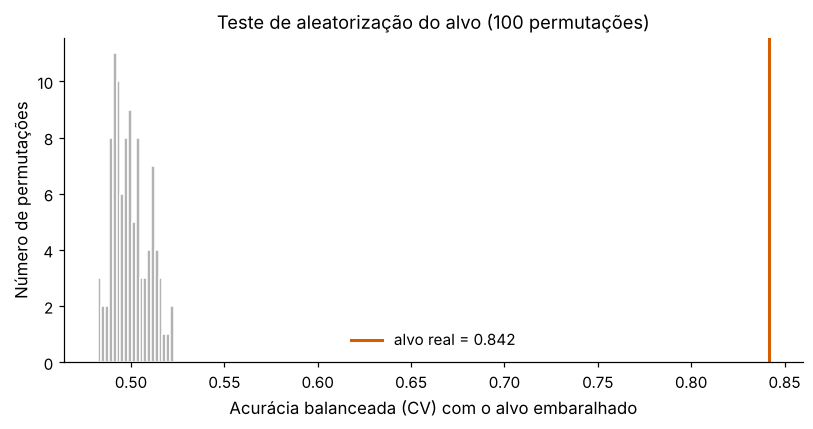

In [18]:
N_PERMUTACOES = 100
cv_perm = validacao_cruzada_otimizacao()
real = cross_validate(pipeline_com_parametros(melhor, MELHORES_PARAMETROS[melhor]), X_busca, y_busca,
                      cv=cv_perm, scoring="balanced_accuracy")["test_score"].mean()

rng = np.random.default_rng(SEMENTE)
permutados = []
for _ in range(N_PERMUTACOES):
    y_perm = rng.permutation(y_busca.to_numpy())
    resultado = cross_validate(pipeline_com_parametros(melhor, MELHORES_PARAMETROS[melhor]), X_busca,
                               y_perm, cv=cv_perm, scoring="balanced_accuracy")
    permutados.append(resultado["test_score"].mean())
permutados = np.array(permutados)
p_valor = (1 + np.sum(permutados >= real)) / (N_PERMUTACOES + 1)

print(f"Acurácia balanceada com o alvo real: {real:.4f}")
print(f"Acurácia com o alvo embaralhado: média {permutados.mean():.4f}, desvio {permutados.std(ddof=1):.4f}, "
      f"máximo {permutados.max():.4f}")
print(f"Valor-p (permutações): {p_valor:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(permutados, bins=20, color="0.7", edgecolor="white")
ax.axvline(real, color=CORES[3], lw=2, label=f"alvo real = {real:.3f}")
ax.set_xlabel("Acurácia balanceada (CV) com o alvo embaralhado")
ax.set_ylabel("Número de permutações")
ax.set_title(f"Teste de aleatorização do alvo ({N_PERMUTACOES} permutações)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "y_randomization.png", dpi=150)
plt.show()

**Leitura.** Com o alvo real, a acurácia balanceada é 0,842. Com o alvo embaralhado, a média fica em 0,500, com desvio-padrão de 0,010 e máximo de 0,523 em 100 permutações. Nenhuma permutação chegou perto do valor real, e o menor valor-p possível com 100 permutações é 1/101, ou cerca de 0,0099, que é o valor obtido. O resultado indica que o modelo aprendeu uma relação entre atributos e renda, e não um padrão produzido pelo procedimento de validação.

## 15. Interpretação do modelo

A interpretação usa o modelo final reajustado no treino completo e as previsões no teste. Todas as análises trabalham com os atributos originais, e não com as colunas codificadas, para que os resultados possam ser lidos em termos de pessoas.

### 15.1 Importância por permutação

Para cada atributo, seus valores são embaralhados no teste e mede-se a queda na acurácia balanceada. Quanto maior a queda, mais o modelo depende do atributo. Essa medida é global e não depende de suposições sobre a forma do modelo, mas atributos correlacionados podem dividir a importância entre si.

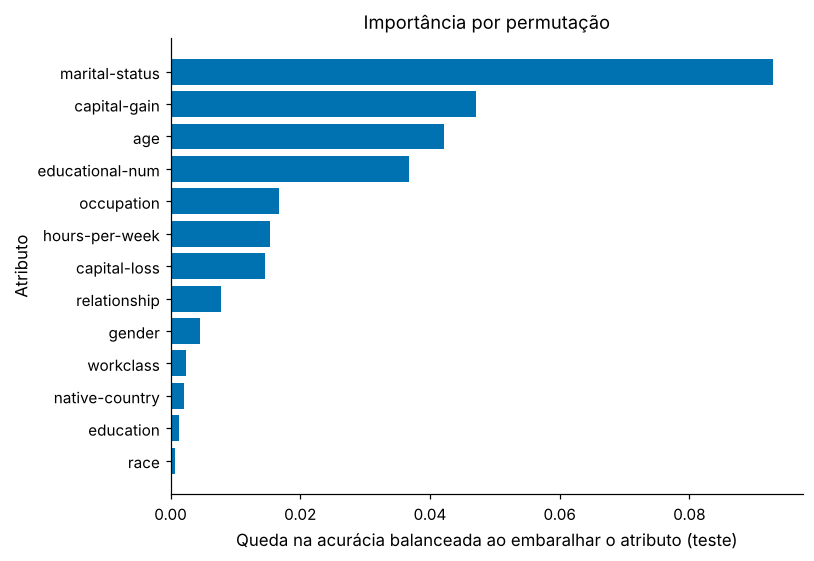

In [19]:
resultado_pi = permutation_importance(modelo_final, X_teste, y_teste, scoring="balanced_accuracy",
                                      n_repeats=10, random_state=SEMENTE, n_jobs=1)
importancia = pd.Series(resultado_pi.importances_mean, index=ATRIBUTOS).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(importancia.index, importancia.values, color=CORES[0])
ax.set_xlabel("Queda na acurácia balanceada ao embaralhar o atributo (teste)")
ax.set_ylabel("Atributo")
ax.set_title("Importância por permutação")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "importancia_permutacao.png", dpi=150)
plt.show()

### 15.2 Valores SHAP

Os valores SHAP (Lundberg e Lee, 2017) distribuem a diferença entre a previsão de uma pessoa e a previsão média entre seus atributos. Usou-se o explicador por permutação com dados de fundo de 100 registros do treino, em 200 pessoas do teste. Para os atributos categóricos, o SHAP trabalha com os códigos das categorias, por isso o gráfico de enxame mostra apenas os atributos numéricos. Na cor de cada ponto, vermelho indica valor alto do atributo e azul, valor baixo.

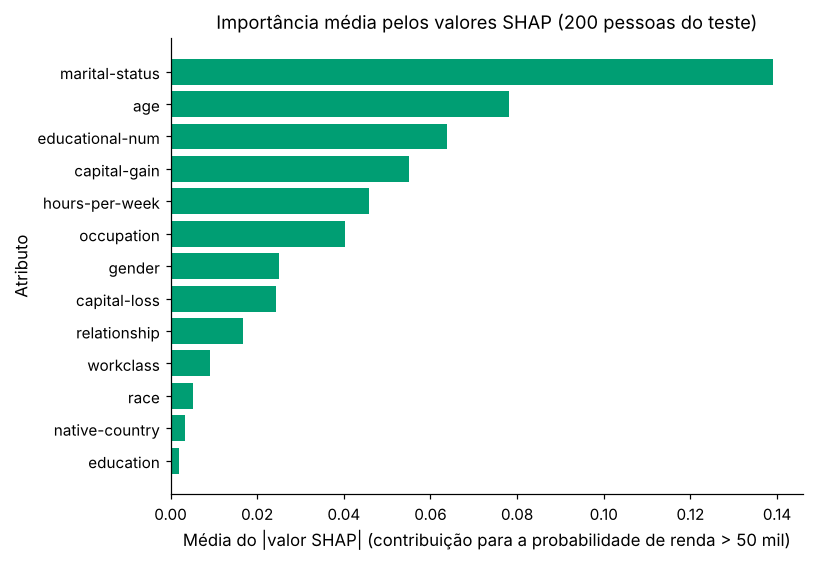

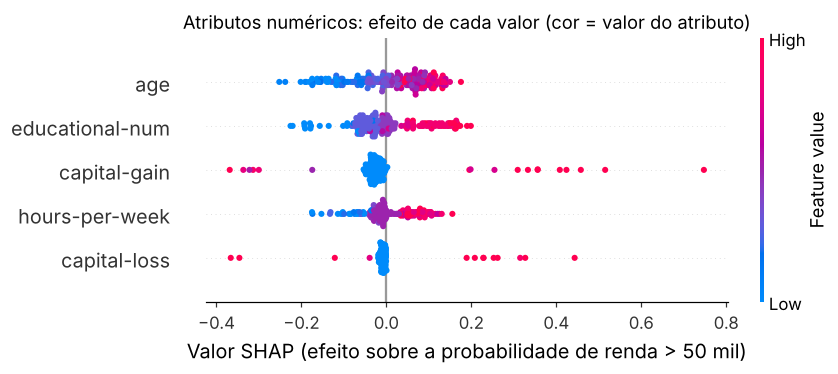

In [20]:
CATEGORIAS = {c: X_treino[c].astype("category").cat.categories for c in ATRIBUTOS_CATEGORICOS}

def para_codigos(df):
    """Converte o DataFrame de atributos em números (códigos das categorias), para o SHAP."""
    saida = pd.DataFrame(index=df.index)
    for c in ATRIBUTOS:
        if c in ATRIBUTOS_CATEGORICOS:
            saida[c] = pd.Categorical(df[c], categories=CATEGORIAS[c]).codes.astype(float)
        else:
            saida[c] = df[c].astype(float)
    return saida

def de_codigos(A):
    df = pd.DataFrame(A, columns=ATRIBUTOS)
    for c in ATRIBUTOS_CATEGORICOS:
        indices = np.clip(np.round(df[c]).astype(int), 0, len(CATEGORIAS[c]) - 1)
        df[c] = CATEGORIAS[c][indices]
    return df[ATRIBUTOS]

def prob_alta_renda(A):
    return modelo_final.predict_proba(de_codigos(A))[:, 1]

fundo = para_codigos(X_treino.sample(100, random_state=SEMENTE))
amostra_shap = para_codigos(X_teste.sample(200, random_state=SEMENTE))
explicador = shap.PermutationExplainer(prob_alta_renda, shap.maskers.Independent(fundo, max_samples=100))
valores = explicador(amostra_shap, max_evals=2 * len(ATRIBUTOS) * 2 + 1, silent=True)
valores.feature_names = ATRIBUTOS

media_abs = pd.Series(np.abs(valores.values).mean(axis=0), index=ATRIBUTOS).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(media_abs.index, media_abs.values, color=CORES[2])
ax.set_xlabel("Média do |valor SHAP| (contribuição para a probabilidade de renda > 50 mil)")
ax.set_ylabel("Atributo")
ax.set_title("Importância média pelos valores SHAP (200 pessoas do teste)")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "shap_importancia_media.png", dpi=150)
plt.show()

indices_numericos = [ATRIBUTOS.index(a) for a in ATRIBUTOS_NUMERICOS]
plt.figure()
shap.plots.beeswarm(valores[:, indices_numericos], show=False, max_display=len(indices_numericos))
plt.xlabel("Valor SHAP (efeito sobre a probabilidade de renda > 50 mil)")
plt.title("Atributos numéricos: efeito de cada valor (cor = valor do atributo)")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura.** Os valores SHAP e a importância por permutação concordam em boa parte da ordem. Nas duas análises, o estado civil é o atributo mais influente. Na categoria casado com cônjuge civil, a renda alta é mais frequente, o que pode refletir a renda do casal e não apenas da pessoa, e por isso o atributo deve ser lido com cautela. Idade, escolaridade e ganho de capital aparecem em seguida. O sexo tem peso pequeno em ambas as análises, e a raça tem o menor peso, o que não significa que o modelo trate os grupos de forma igual (ver seção 15.4).

Na dependência parcial, a probabilidade média de renda alta sobe com a idade até cerca de 50 anos, mantém-se até aproximadamente 65 e diminui depois. Ela também sobe quando as horas semanais passam de 35 a 40 horas.

### 15.3 Dependência parcial

Os gráficos de dependência parcial mostram como a probabilidade prevista muda quando um atributo varia e os demais são mantidos na distribuição dos dados. As linhas cinzas são pessoas individuais, e a linha azul é a média. Eles mostram tendências médias do modelo e não relações causais.

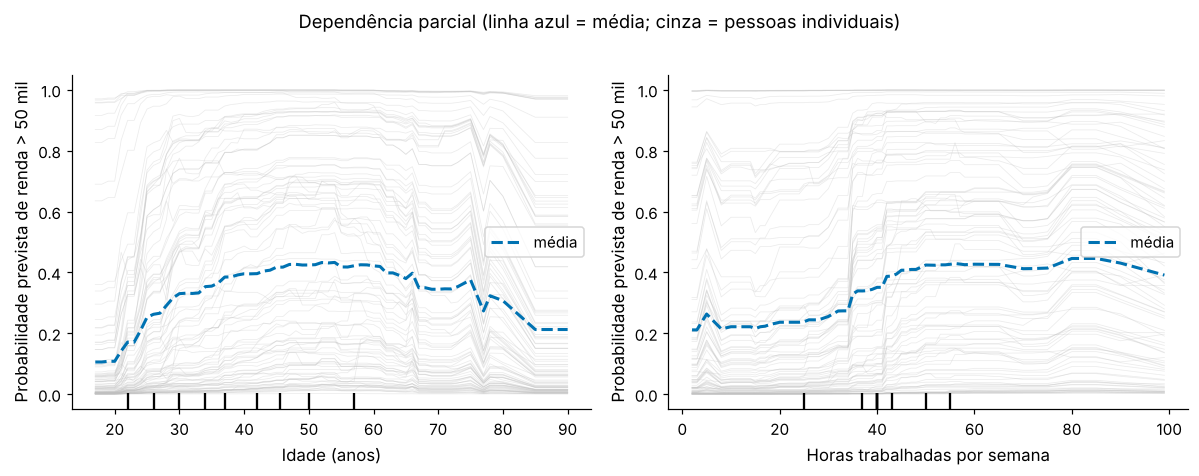

In [21]:
amostra_pdp = X_treino.sample(1000, random_state=SEMENTE).copy()
amostra_pdp[["age", "hours-per-week"]] = amostra_pdp[["age", "hours-per-week"]].astype(float)
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
PartialDependenceDisplay.from_estimator(modelo_final, amostra_pdp, features=["age", "hours-per-week"],
                                        kind="both", ax=eixos, subsample=100, random_state=SEMENTE,
                                        ice_lines_kw={"color": "0.75", "alpha": 0.3},
                                        pd_line_kw={"color": CORES[0], "lw": 2})
for eixo in eixos:
    if eixo.get_legend() is not None:
        eixo.get_legend().get_texts()[0].set_text("média")
eixos[0].set_xlabel("Idade (anos)")
eixos[1].set_xlabel("Horas trabalhadas por semana")
for eixo in eixos:
    eixo.set_ylabel("Probabilidade prevista de renda > 50 mil")
fig.suptitle("Dependência parcial (linha azul = média; cinza = pessoas individuais)", y=1.02)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "dependencia_parcial.png", dpi=150, bbox_inches="tight")
plt.show()

### 15.4 Desempenho por grupo

Esta análise compara sensibilidade, especificidade e acurácia balanceada entre grupos de sexo e de raça com pelo menos 50 pessoas no teste. Diferenças entre grupos são um sinal de que o modelo pode tratar pessoas de forma desigual, ainda que o sexo ou a raça não sejam atributos explícitos de decisão. Os grupos menores têm estimativas menos precisas, e isso deve ser levado em conta na leitura da tabela.

In [22]:
previsto = pd.Series(pred, index=X_teste.index)
linhas_sub = []
for atributo in ["gender", "race"]:
    for grupo, idx in X_teste.groupby(atributo).groups.items():
        if len(idx) < 50:
            continue
        verdade = y_teste.loc[idx]
        estimado = previsto.loc[idx]
        pos = verdade == 1
        neg = verdade == 0
        linhas_sub.append({
            "atributo": atributo,
            "grupo": grupo,
            "pessoas no teste": len(idx),
            "renda real > 50 mil (%)": round(100 * pos.mean(), 1),
            "sensibilidade": round((estimado[pos] == 1).mean(), 3),
            "especificidade": round((estimado[neg] == 0).mean(), 3),
            "acurácia balanceada": round(balanced_accuracy_score(verdade, estimado), 3),
        })
tabela_sub = pd.DataFrame(linhas_sub)
display(tabela_sub)

,atributo,grupo,pessoas no teste,renda real > 50 mil (%),sensibilidade,especificidade,acurácia balanceada
0,gender,Female,1956,11.8,0.749,0.939,0.844
1,gender,Male,4072,31.2,0.876,0.754,0.815
2,race,Amer-Indian-Eskimo,63,9.5,0.667,0.772,0.719
3,race,Asian-Pac-Islander,174,23.6,0.878,0.782,0.830
4,race,Black,594,13.8,0.841,0.904,0.873
5,race,White,5150,26.6,0.857,0.814,0.836


**Leitura.** A acurácia balanceada é parecida entre mulheres (0,844) e homens (0,815), mas os erros se distribuem de forma diferente. A sensibilidade é de 0,749 para mulheres e de 0,876 para homens: o modelo deixa de identificar uma proporção maior de mulheres de alta renda. Isso acontece em um grupo em que apenas 11,8 % das mulheres do teste têm renda acima de 50 mil dólares, contra 31,2 % dos homens. Entre os grupos raciais com pelo menos 50 pessoas, o desempenho é semelhante para pessoas brancas (0,836), negras (0,873) e asiáticas ou das ilhas do Pacífico (0,830). O grupo de indígenas americanos e nativos do Alasca tem apenas 63 pessoas no teste, o que torna sua estimativa pouco precisa.

Essa diferença não prova discriminação, mas mostra que um modelo com bom desempenho médio pode errar de forma desigual entre grupos. Isso deve ser avaliado antes de qualquer uso real.

## 16. Limitações e perspectivas

- **Dados antigos.** Os registros são de 1994. Renda, ocupações e a relação entre escolaridade e salário mudaram desde então, e o modelo não deve ser usado para decisões atuais sem nova validação.
- **Subamostra na busca.** A busca de hiperparâmetros e a comparação usam 6.000 registros do treino, e não os cerca de 24 mil disponíveis. O modelo final é reajustado no treino completo, mas os hiperparâmetros foram escolhidos com menos dados, o que pode fazer com que a configuração ótima seja diferente com todo o treino.
- **Atributos redundantes.** `education` e `educational-num` representam a mesma informação. Modelos baseados em árvores lidam bem com isso, mas a regressão logística pode dividir a importância entre os dois.
- **Atributos sensíveis.** `gender` e `race` são mantidos porque fazem parte do conjunto de dados, mas seu uso em decisões reais exige cuidado jurídico e ético. A análise da seção 15.4 mostra apenas parte do problema de equidade.
- **Teste de aleatorização.** Os hiperparâmetros foram mantidos fixos. Uma versão completa repetiria a busca em cada permutação, o que custaria muito tempo.
- **Sem análise de limiar.** As previsões usam o limiar padrão de 0,5 nas probabilidades. A escolha de outro limiar mudaria o equilíbrio entre falsos positivos e falsos negativos.
- **Sem validação externa.** O teste vem da mesma amostra do censo. Não há avaliação em outra população.

In [23]:
print(f"Tempo total de execução do notebook: {(time.perf_counter() - INICIO_NOTEBOOK) / 60:.1f} min")

Tempo total de execução do notebook: 10.4 min


## 17. Descrição do uso de IA neste trabalho

✏️ **Esta seção deve ser escrita pela autora, em primeira pessoa, com as próprias palavras.** O rascunho abaixo descreve os fatos do processo e serve de base para a sua versão. Ele não substitui a sua descrição.

Este trabalho foi desenvolvido com o auxílio do assistente de IA Claude (Anthropic), usado como ferramenta de apoio em programação e escrita. A IA ajudou a reescrever o código para trabalhar com atributos numéricos e categóricos, a organizar o projeto em módulos, a estruturar a validação cruzada e a verificar se os textos do notebook correspondem às saídas. Ao conferir a limpeza dos dados, a IA identificou que remover duplicatas considerando apenas os 13 atributos apagava registros de pessoas distintas, e a regra foi corrigida antes da otimização. A escolha da pergunta, do conjunto de dados, dos algoritmos, do espaço de busca e das conclusões foi feita pela autora, e cada resultado foi conferido na execução do notebook.

✏️ [Autora: acrescente aqui o que você fez sozinha, quais decisões tomou, o que verificou manualmente e o que mudaria no processo.]

## 18. Conclusões e principais aprendizados

O gradient boosting foi o algoritmo com maior desempenho na validação cruzada repetida (0,840) e no teste (acurácia balanceada de 0,840 e ROC AUC de 0,925). Ele ficou estatisticamente empatado com o LightGBM, que é uma implementação do mesmo princípio, e superou os demais algoritmos, inclusive a floresta aleatória, embora essa vantagem seja pequena, da ordem de 0,01. A árvore de decisão isolada ficou atrás das versões em conjunto, o que mostra o ganho de combinar muitas árvores. O k-NN foi o pior, o que é coerente com sua sensibilidade à escala e ao número de atributos e reforça que o pré-processamento faz parte da escolha do modelo.

Entre os aprendizados técnicos, destaco quatro. Primeiro, a validação cruzada apenas no treino, com a normalização e a codificação dentro do pipeline, evitou que o desempenho fosse inflado: o resultado no teste ficou igual ao da validação. Segundo, as decisões de dados, como remover duplicatas e deixar de fora o `fnlwgt`, mudam o tamanho e o sentido do problema, e precisam ser justificadas, não apenas executadas. Terceiro, a busca de hiperparâmetros em uma subamostra foi uma concessão para caber no prazo. Ela não impediu bons resultados, já que o modelo final teve o mesmo desempenho no teste, mas é uma limitação registrada. Quarto, o teste de aleatorização mostrou que o modelo aprendeu um padrão real.

Na interpretação, o estado civil, a idade, a escolaridade e o ganho de capital são os atributos mais influentes. A análise por grupo, porém, trouxe o principal alerta do trabalho: o modelo identifica menos mulheres de alta renda (sensibilidade de 0,749) do que homens (0,876). Um modelo com boa média pode errar de forma desigual, e isso precisa ser avaliado antes de qualquer uso real.

Como próximos passos, faria a busca com todo o treino, escolheria o limiar de decisão de acordo com o custo de cada tipo de erro, testaria o modelo sem os atributos sensíveis e avaliaria seu desempenho em dados mais recentes.

## 19. Referências

Akiba, T., Sano, S., Yanase, T., Ohta, T., e Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2623–2631.

Barocas, S., Hardt, M., e Narayanan, A. (2023). *Fairness and machine learning: Limitations and opportunities*. MIT Press.

Becker, B., e Kohavi, R. (1996). Adult [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20

Bergstra, J., Bardenet, R., Bengio, Y., e Kégl, B. (2011). Algorithms for hyper-parameter optimization. *Advances in Neural Information Processing Systems*, 24.

Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.

Breiman, L., Friedman, J. H., Olshen, R. A., e Stone, C. J. (1984). *Classification and regression trees*. Wadsworth.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics*, 29(5), 1189–1232.

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., e Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30.

Kohavi, R. (1996). Scaling up the accuracy of naive-Bayes classifiers: A decision-tree hybrid. *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)*, 202–207.

Lundberg, S. M., e Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.

Nadeau, C., e Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239–281.

Ojala, M., e Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research*, 11, 1833–1863.

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.